# Measuring nonlinear dependence with information

Mutual information measures how much knowing either variable reduces uncertainty about the other:

$$
I(X;Y)=\sum_{x,y}p(x,y)\log\frac{p(x,y)}{p(x)p(y)}
=H(X)+H(Y)-H(X,Y).
$$

Here, $X$ and $Y$ are discretized random variables; $x$ and $y$ are possible values. $p(x,y)$ is their joint probability; $p(x),p(y)$ are marginal probabilities; $H$ denotes entropy; $\log$ uses one fixed base.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("09_dependence_geometry_information");
using CSV, Printf
using RiskLabAI.Data: calculate_distance,calculate_mutual_information,calculate_number_of_bins,calculate_variation_of_information,calculate_variation_of_information_extended,distance_correlation,ksg_mutual_information
using RiskLabAI.Features: shannon_entropy,probability_mass_function,plug_in_entropy_estimator,lempel_ziv_entropy,kontoyiannis_entropy,miller_madow_entropy,grassberger_entropy,nsb_entropy
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute_close = raw.close
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
return_values,return_index = diff(log_price),close_index[2:end]
violet = "#C084FC"

function contingency_counts(x,y,bins)
    xedges,yedges = collect(range(extrema(x)...;length=bins+1)),collect(range(extrema(y)...;length=bins+1))
    counts = zeros(Int,bins,bins)
    for (left,right) in zip(x,y)
        counts[min(searchsortedlast(xedges,left),bins),min(searchsortedlast(yedges,right),bins)] += 1
    end
    return counts
end

function histogram_information(counts)
    probability = counts./sum(counts)
    marginal_x,marginal_y = vec(sum(probability;dims=2)),vec(sum(probability;dims=1))
    entropy(values) = -sum(value*log(value) for value in values if value>0)
    entropy_x,entropy_y,joint = entropy(marginal_x),entropy(marginal_y),entropy(probability)
    information = sum(probability[left,right]*log(probability[left,right]/(marginal_x[left]*marginal_y[right])) for left in axes(counts,1),right in axes(counts,2) if probability[left,right]>0)
    variation = entropy_x+entropy_y-2information
    return (information=information,joint=joint,variation=variation,normalized_mi=information/min(entropy_x,entropy_y),normalized_vi=variation/joint)
end


histogram_information (generic function with 1 method)

## Separating shared information from remaining variation

Variation of information adds what remains uncertain in each variable after the other is known, and normalization places the value between zero and one:

$$
\operatorname{VI}(X,Y)=H(X)+H(Y)-2I(X;Y),
\qquad
\widetilde{\operatorname{VI}}(X,Y)=\frac{\operatorname{VI}(X,Y)}{H(X,Y)}.
$$

Here, $H(X)$ and $H(Y)$ are marginal entropies; $H(X,Y)$ is joint entropy; $I(X;Y)$ is mutual information. $\operatorname{VI}(X,Y)$ is variation of information; $\widetilde{\operatorname{VI}}(X,Y)$ is its joint-entropy normalization.

In [2]:
pair_data = [("Return and one-step lag",return_values[2:end],return_values[1:end-1]),("Return and absolute return",return_values,abs.(return_values)),("Return and squared return",return_values,return_values.^2),("One- and four-interval returns",log_price[5:end].-log_price[4:end-1],log_price[5:end].-log_price[1:end-4])]
dependence_rows,identity_rows,histogram_rows = NamedTuple[],NamedTuple[],NamedTuple[]
for (label,x,y) in pair_data
    correlation_value = cor(x,y)
    bins = calculate_number_of_bins(length(x);correlation=correlation_value)
    normalized_mi = calculate_mutual_information(x,y;norm=true)
    normalized_vi = calculate_variation_of_information_extended(x,y;norm=true)
    counts = contingency_counts(x,y,bins)
    information = histogram_information(counts)
    variation_released = calculate_variation_of_information(x,y,bins;norm=false)
    push!(dependence_rows,(pair=label,observations=length(x),bins=bins,correlation=correlation_value,mi=normalized_mi,vi=normalized_vi))
    push!(identity_rows,(pair=label,mi=information.information,joint=information.joint,identity=information.variation,released=variation_released,difference=abs(information.variation-variation_released)))
    for left in 1:bins,right in 1:bins
        push!(histogram_rows,(kind="Automatic",pair=label,bins=bins,left=left,right=right,count=counts[left,right]))
    end
end
dependence_summary,information_identity_checks = DataFrame(dependence_rows),DataFrame(identity_rows)
rename!(dependence_summary,["Pair","Observations","Bins","Correlation","Normalized mutual information","Normalized variation of information"])
rename!(information_identity_checks,["Pair","Mutual information","Joint entropy","Variation from identity","Released variation","Absolute difference"])
save_table(dependence_summary,paths,"dependence_summary";caption="Linear and information-based dependence for public return pairs.",label="tab:chapter8-dependence-summary")
save_table(information_identity_checks,paths,"information_identity_checks";caption="Independent checks of the variation-of-information identity.",label="tab:chapter8-information-identity")


Row,Pair,Observations,Bins,Correlation,Normalized mutual information,Normalized variation of information
,String,Int64,Int64,Float64,Float64,Float64
1,Return and one-step lag,2974,12,-0.0236608,0.0381338,0.980563
2,Return and absolute return,2975,12,0.0617844,0.653331,0.610269
3,Return and squared return,2975,12,0.147051,0.793022,0.935375
4,One- and four-interval returns,2972,12,0.476218,0.12404,0.93615


Row,Pair,Mutual information,Joint entropy,Variation from identity,Released variation,Absolute difference
,String,Float64,Float64,Float64,Float64,Float64
1,Return and one-step lag,0.0391296,2.0131,1.97397,1.97397,2.22045e-16
2,Return and absolute return,0.504073,1.29339,0.789315,0.789315,2.22045e-16
3,Return and squared return,0.0674374,1.04352,0.976081,0.976081,0.0
4,One- and four-interval returns,0.127328,1.99417,1.86684,1.86684,6.66134e-16


## Choosing Bins

The released rule chooses the same number of histogram bins for two continuous variables using sample size and their estimated correlation:

$$
B=\operatorname{round}\!\left[
\frac{1}{\sqrt{2}}
\sqrt{1+\sqrt{1+\frac{24N}{1-\widehat\rho^{\,2}}}}
\right].
$$

Here, $B$ is the chosen bin count; $N$ is the number of paired observations; $\widehat\rho$ is their sample correlation. $\operatorname{round}$ selects the nearest integer; the formula requires $|\widehat\rho|<1$ before numerical endpoint handling.

In [3]:
_,nonlinear_x,nonlinear_y = pair_data[2]
_,lag_x,lag_y = pair_data[1]
sensitivity_rows = NamedTuple[]
for bins in [4,6,8,10,12,16,20,30,40]
    for (label,x,y) in [pair_data[2],pair_data[1]]
        counts = contingency_counts(x,y,bins)
        information = histogram_information(counts)
        push!(sensitivity_rows,(pair=label,bins=bins,mi=information.normalized_mi,vi=information.normalized_vi))
        for left in 1:bins,right in 1:bins
            push!(histogram_rows,(kind="Sensitivity",pair=label,bins=bins,left=left,right=right,count=counts[left,right]))
        end
    end
end
information_bin_sensitivity = DataFrame(sensitivity_rows)
rename!(information_bin_sensitivity,["Pair","Bins","Normalized mutual information","Normalized variation of information"])
save_table(information_bin_sensitivity,paths,"information_bin_sensitivity";caption="Dependence estimates under several fixed bin counts.",label="tab:chapter8-bin-sensitivity")
save_data(DataFrame(histogram_rows),paths,"dependence_histogram_counts");


Row,Pair,Bins,Normalized mutual information,Normalized variation of information
,String,Int64,Float64,Float64
1,Return and absolute return,4,0.706926,0.671647
2,Return and one-step lag,4,0.0565856,0.970883
3,Return and absolute return,6,0.538365,0.767438
4,Return and one-step lag,6,0.042398,0.978342
5,Return and absolute return,8,0.29274,0.886063
6,Return and one-step lag,8,0.0204116,0.989689
7,Return and absolute return,10,0.370382,0.827265
8,Return and one-step lag,10,0.0230139,0.98836
9,Return and absolute return,12,0.653331,0.610269


## Known-Truth Information Tests

The first expression gives the exact information shared by two jointly normal variables, while the second estimates shared information from nearby observations:

$$
I_{\mathrm G}(\rho)=-\frac{1}{2}\log_2(1-\rho^2),
\qquad
\widehat I_{\mathrm{NN}}
=\psi(k)+\psi(N)-\frac{1}{N}\sum_{i=1}^{N}
\left[\psi(n_{x,i}+1)+\psi(n_{y,i}+1)\right].
$$

Here, $I_{\mathrm G}(\rho)$ is exact mutual information in bits; $\rho\in(-1,1)$ is correlation; $\log_2$ uses base two. $\widehat I_{\mathrm{NN}}$ is the nearest-neighbor estimate in natural-log units; $N$ is sample size; $k$ is the chosen neighbor count. $\psi$ is the digamma function; $n_{x,i}$ and $n_{y,i}$ count marginal neighbors around observation $i.$

Distance correlation compares centered pairwise distances and can detect both straight and curved dependence:

$$
\operatorname{dCor}(X,Y)
=\sqrt{\frac{\overline{AB}}{\sqrt{\overline{A^2}\,\overline{B^2}}}}.
$$

Here, $X$ and $Y$ are paired variables; $A$ and $B$ are their double-centered distance matrices. $\overline{AB}$ is the mean entrywise product; $\overline{A^2}$ and $\overline{B^2}$ are mean squared entries; $\operatorname{dCor}\in[0,1].$

Row,Relation,Sample size,Method,True information in bits,Mean estimate in bits,Estimate standard deviation,Root mean squared error
,String,Int64,String,Float64,Float64,Float64,Float64
1,Straight Gaussian relation,200,Nearest-neighbor estimate,0.485715,0.49857,0.133227,0.12935
2,Straight Gaussian relation,200,Binned estimate,0.485715,0.507973,0.0774887,0.0781
3,Straight Gaussian relation,1000,Nearest-neighbor estimate,0.485715,0.488096,0.0279634,0.0271199
4,Straight Gaussian relation,1000,Binned estimate,0.485715,0.478023,0.0293947,0.0294214
5,Monotone cubic relation,1000,Nearest-neighbor estimate,0.485715,0.443636,0.0314682,0.0519124
6,Monotone cubic relation,1000,Binned estimate,0.485715,0.272069,0.0503417,0.219112


Row,Relation,Pearson correlation,Distance correlation,Nearest-neighbor information in bits
,String,Float64,Float64,Float64
1,Independent,0.0120068,0.0745328,-0.0139753
2,Straight,0.698418,0.64804,0.487443
3,Curved,0.0336586,0.533215,2.47386


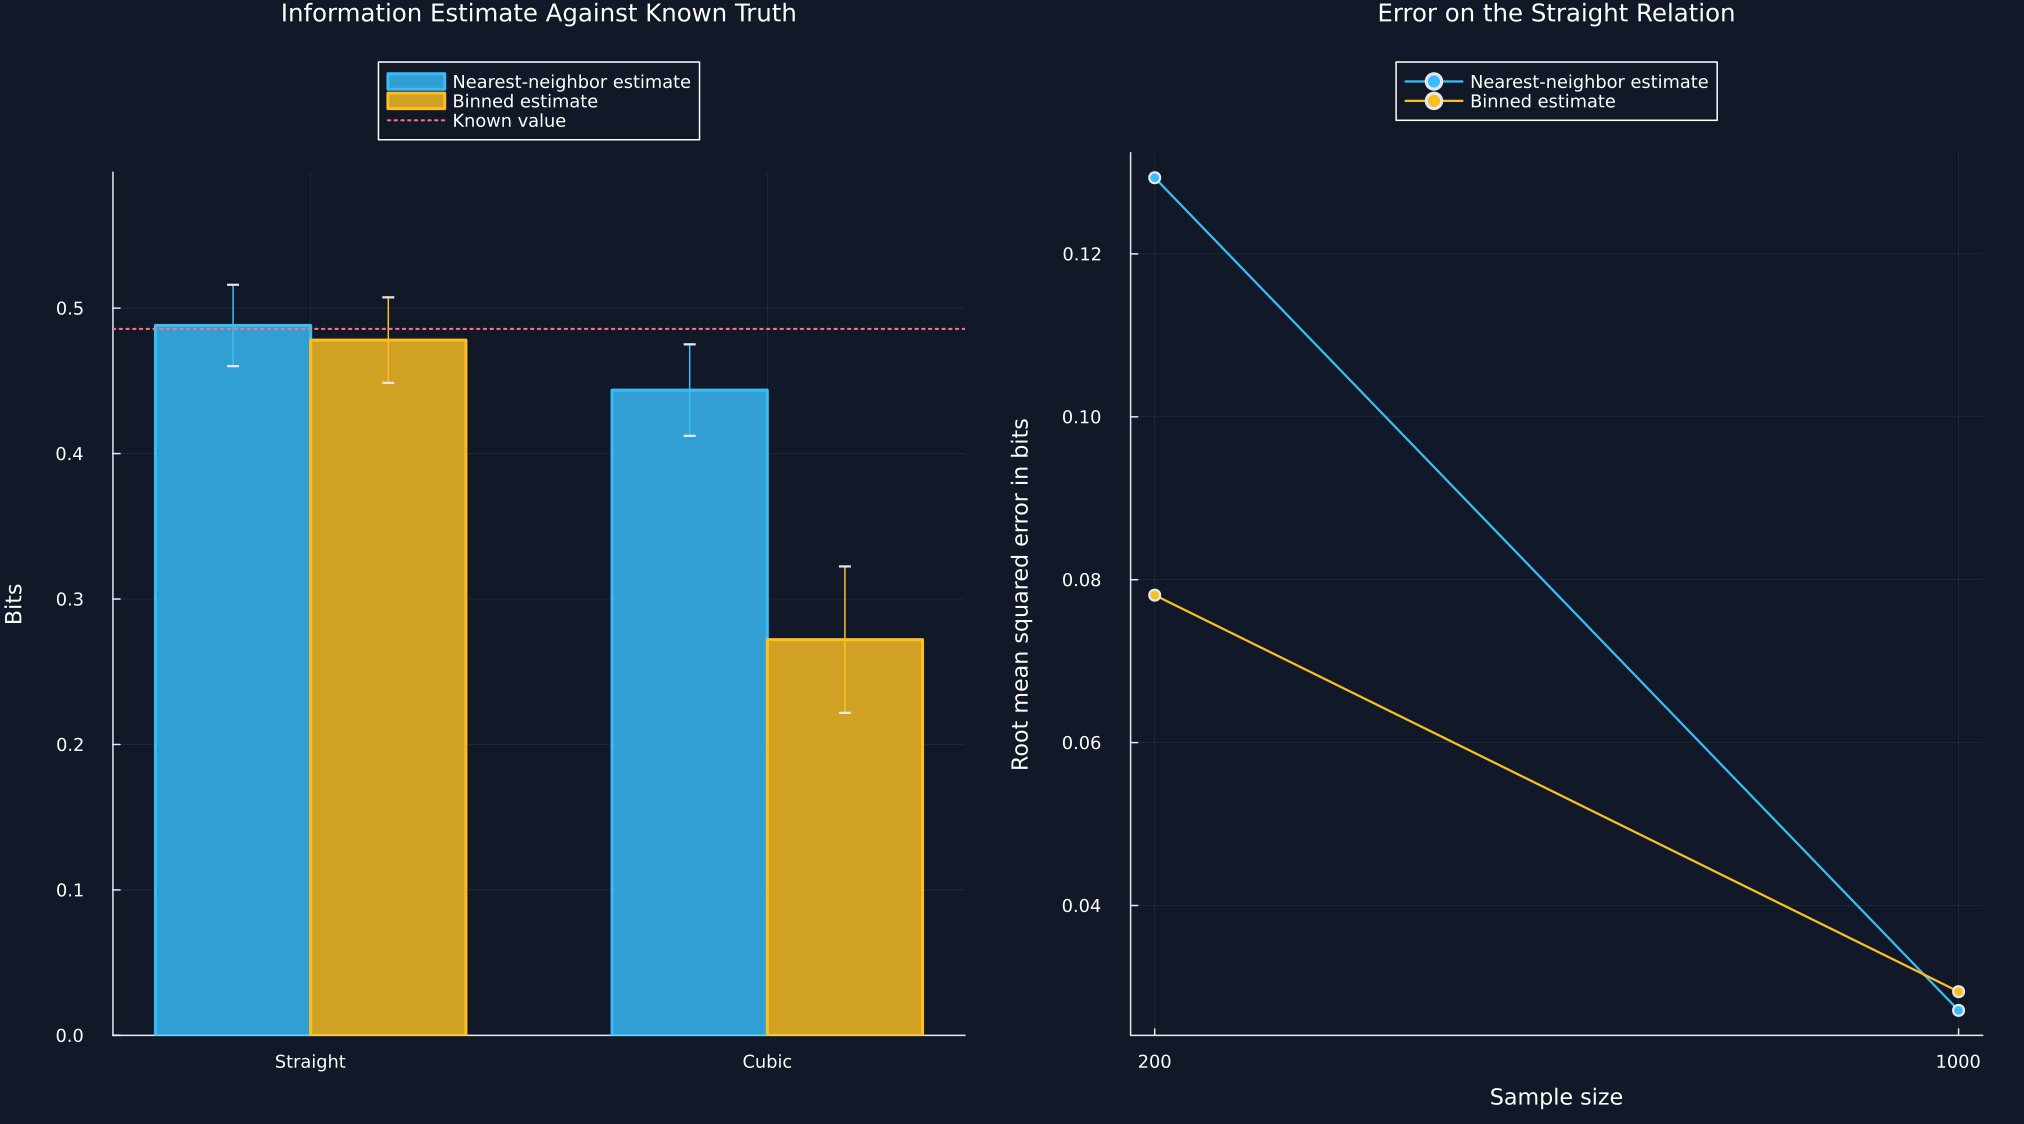

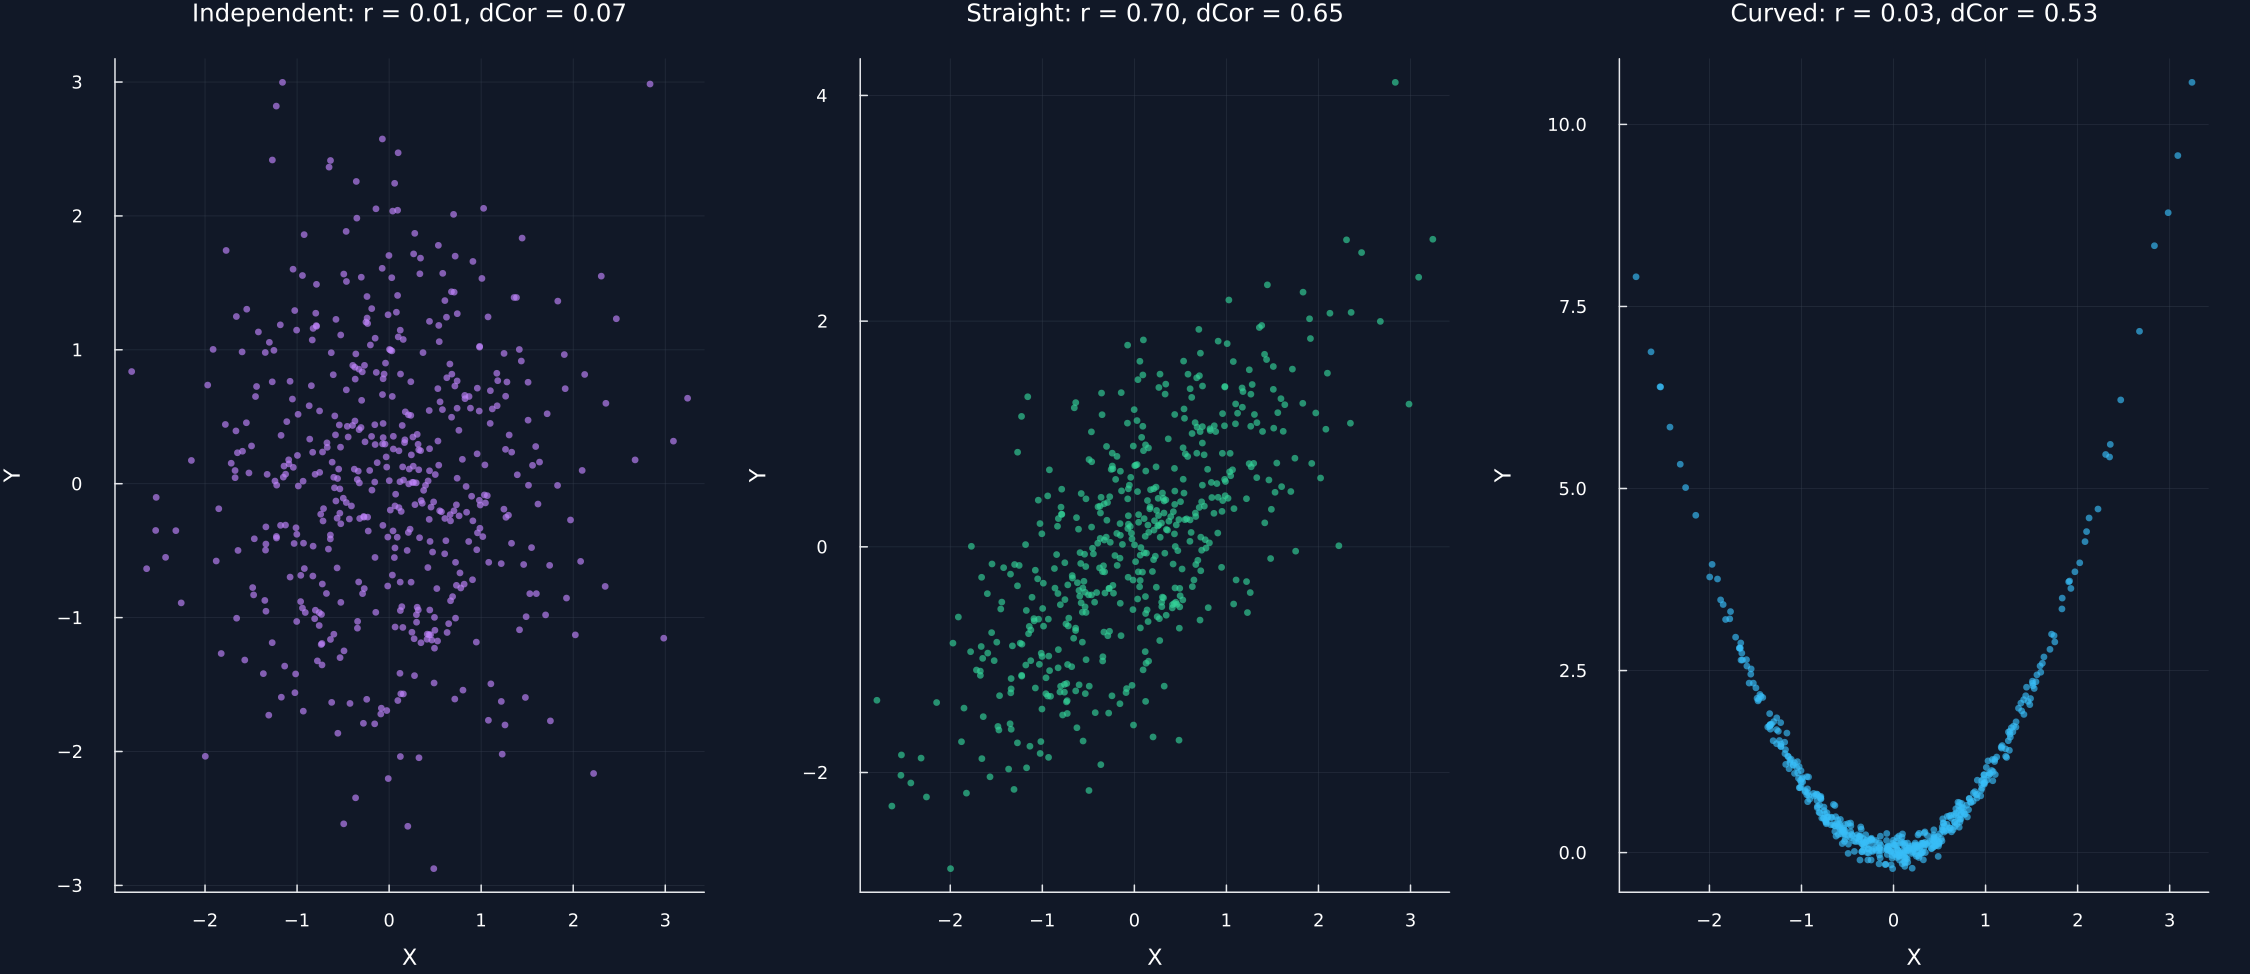

In [4]:
log_two,known_correlation = log(2.),.70
true_information = -.5*log(1-known_correlation^2)/log_two
information_runs,information_draws,individual_information = NamedTuple[],NamedTuple[],NamedTuple[]
stored_information = Dict{Tuple{String,Int,String},Vector{Float64}}()
for (relation,sample_size) in [("Straight Gaussian relation",200),("Straight Gaussian relation",1000),("Monotone cubic relation",1000)]
    nearest_values,binned_values = Float64[],Float64[]
    for seed in 0:14
        random_generator = Xoshiro(seed)
        common_driver = randn(random_generator,sample_size)
        innovation = randn(random_generator,sample_size)
        if relation=="Straight Gaussian relation"
            x_values = common_driver
            y_values = known_correlation.*common_driver.+sqrt(1-known_correlation^2).*innovation
        else
            x_values = known_correlation.*common_driver.+sqrt(1-known_correlation^2).*innovation
            y_values = common_driver.^3
        end
        jitter_generator = Xoshiro(seed)
        x_jitter,y_jitter = randn(jitter_generator,sample_size),randn(jitter_generator,sample_size)
        nearest = ksg_mutual_information(x_values,y_values;k=4,random_state=seed,jitter_draws=(x_jitter,y_jitter))/log_two
        binned = calculate_mutual_information(x_values,y_values)/log_two
        push!(nearest_values,nearest)
        push!(binned_values,binned)
        push!(individual_information,(relation=relation,sample_size=sample_size,seed=seed,nearest=nearest,binned=binned))
        for position in 1:sample_size
            push!(information_draws,(relation=relation,sample_size=sample_size,seed=seed,position=position,driver=common_driver[position],innovation=innovation[position],x=x_values[position],y=y_values[position],x_jitter=x_jitter[position],y_jitter=y_jitter[position]))
        end
    end
    for (method,values) in [("Nearest-neighbor estimate",nearest_values),("Binned estimate",binned_values)]
        stored_information[(relation,sample_size,method)] = values
        push!(information_runs,(relation=relation,size=sample_size,method=method,truth=true_information,mean=mean(values),sd=std(values),rmse=sqrt(mean((values.-true_information).^2))))
    end
end
known_truth_information_summary = DataFrame(information_runs)
rename!(known_truth_information_summary,["Relation","Sample size","Method","True information in bits","Mean estimate in bits","Estimate standard deviation","Root mean squared error"])
screen_rows,screen_draws = NamedTuple[],NamedTuple[]
screen_samples = Dict{String,Any}()
for relation in ["Independent","Straight","Curved"],seed in 0:4
    random_generator = Xoshiro(8100+10seed)
    x_values,innovation = randn(random_generator,500),randn(random_generator,500)
    y_values = relation=="Independent" ? innovation : relation=="Straight" ? .7 .* x_values.+sqrt(1-.49).*innovation : x_values.^2 .+.1 .* innovation
    seed==0 && (screen_samples[relation]=(x_values,y_values))
    jitter_generator = Xoshiro(seed)
    x_jitter,y_jitter = randn(jitter_generator,500),randn(jitter_generator,500)
    information = ksg_mutual_information(x_values,y_values;random_state=seed,jitter_draws=(x_jitter,y_jitter))/log_two
    push!(screen_rows,(relation=relation,seed=seed,pearson=cor(x_values,y_values),distance=distance_correlation(x_values,y_values),information=information))
    for position in 1:500
        push!(screen_draws,(relation=relation,seed=seed,position=position,x=x_values[position],innovation=innovation[position],y=y_values[position],x_jitter=x_jitter[position],y_jitter=y_jitter[position]))
    end
end
nonlinear_screen_runs = DataFrame(screen_rows)
nonlinear_screen_summary = combine(groupby(nonlinear_screen_runs,:relation;sort=false),:pearson=>mean=>:pearson,:distance=>mean=>:distance,:information=>mean=>:information)
rename!(nonlinear_screen_summary,["Relation","Pearson correlation","Distance correlation","Nearest-neighbor information in bits"])
save_table(known_truth_information_summary,paths,"known_truth_information_summary";caption="Known-truth information estimates over fifteen fixed seeds.",label="tab:chapter8-known-truth-information")
save_table(nonlinear_screen_summary,paths,"nonlinear_screen_summary";caption="Linear and nonlinear dependence measures for three controlled relations.",label="tab:chapter8-nonlinear-screen")
save_data(DataFrame(information_draws),paths,"known_truth_information_draws")
save_data(DataFrame(individual_information),paths,"known_truth_information_runs")
save_data(DataFrame(screen_draws),paths,"nonlinear_screen_draws")
save_data(nonlinear_screen_runs,paths,"nonlinear_screen_runs")
benchmark_cases = [("Straight Gaussian relation",1000),("Monotone cubic relation",1000)]
method_names,method_colors = ["Nearest-neighbor estimate","Binned estimate"],[palette.cyan,palette.amber]
p1 = plot(;title="Information Estimate Against Known Truth",ylabel="Bits",xticks=(1:2,["Straight","Cubic"]),legend=:outertop,legend_column=1)
p2 = plot(;title="Error on the Straight Relation",xlabel="Sample size",ylabel="Root mean squared error in bits",xscale=:log10,xticks=([200,1000],["200","1000"]),legend=:outertop,legend_column=1)
for (index,(method,color)) in enumerate(zip(method_names,method_colors))
    means = [mean(stored_information[(relation,size,method)]) for (relation,size) in benchmark_cases]
    errors = [std(stored_information[(relation,size,method)]) for (relation,size) in benchmark_cases]
    bar!(p1,(1:2).+(index-1.5)*.34,means;yerror=errors,bar_width=.34,color,fillalpha=.82,linecolor=color,label=method)
    current = known_truth_information_summary[(known_truth_information_summary.Relation.=="Straight Gaussian relation").&(known_truth_information_summary.Method.==method),:]
    plot!(p2,current[!,"Sample size"],current[!,"Root mean squared error"];color,marker=:circle,linewidth=1.5,label=method)
end
hline!(p1,[true_information];color=palette.rose,linestyle=:dot,linewidth=1.4,label="Known value")
ylims!(p1,0.,1.15last(ylims(p1)))
save_figure(plot(p1,p2;layout=(1,2),size=(1350,750)),paths,"known_truth_information")
panels = []
for (relation,color) in zip(["Independent","Straight","Curved"],[violet,palette.green,palette.cyan])
    x_values,y_values = screen_samples[relation]
    row = only(eachrow(nonlinear_screen_summary[nonlinear_screen_summary.Relation.==relation,:]))
    title = @sprintf("%s: r = %.2f, dCor = %.2f",relation,row["Pearson correlation"],row["Distance correlation"])
    push!(panels,scatter(x_values,y_values;color,markersize=2.5,markerstrokewidth=0,alpha=.65,title,titlefontsize=11,xlabel="X",ylabel="Y",legend=false))
end
save_figure(plot(panels...;layout=(1,3),left_margin=6Plots.mm,size=(1500,650)),paths,"controlled_dependence_cases")


## A Public Nonlinear Example

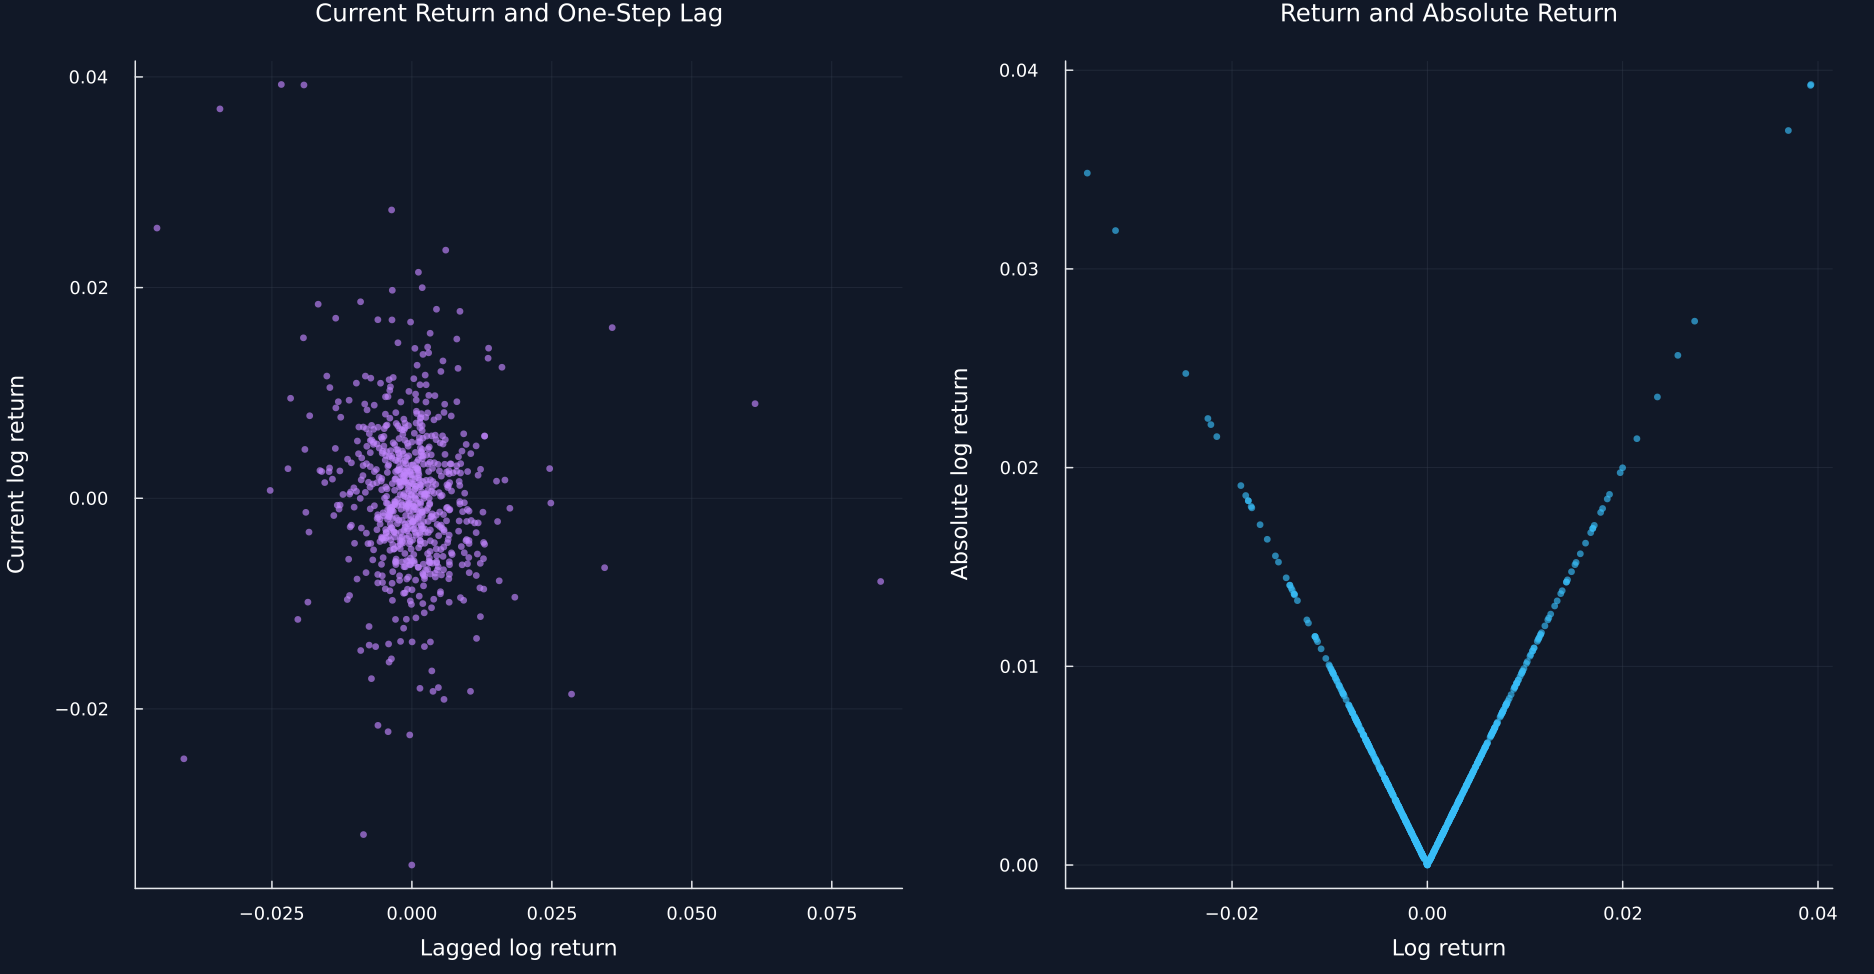

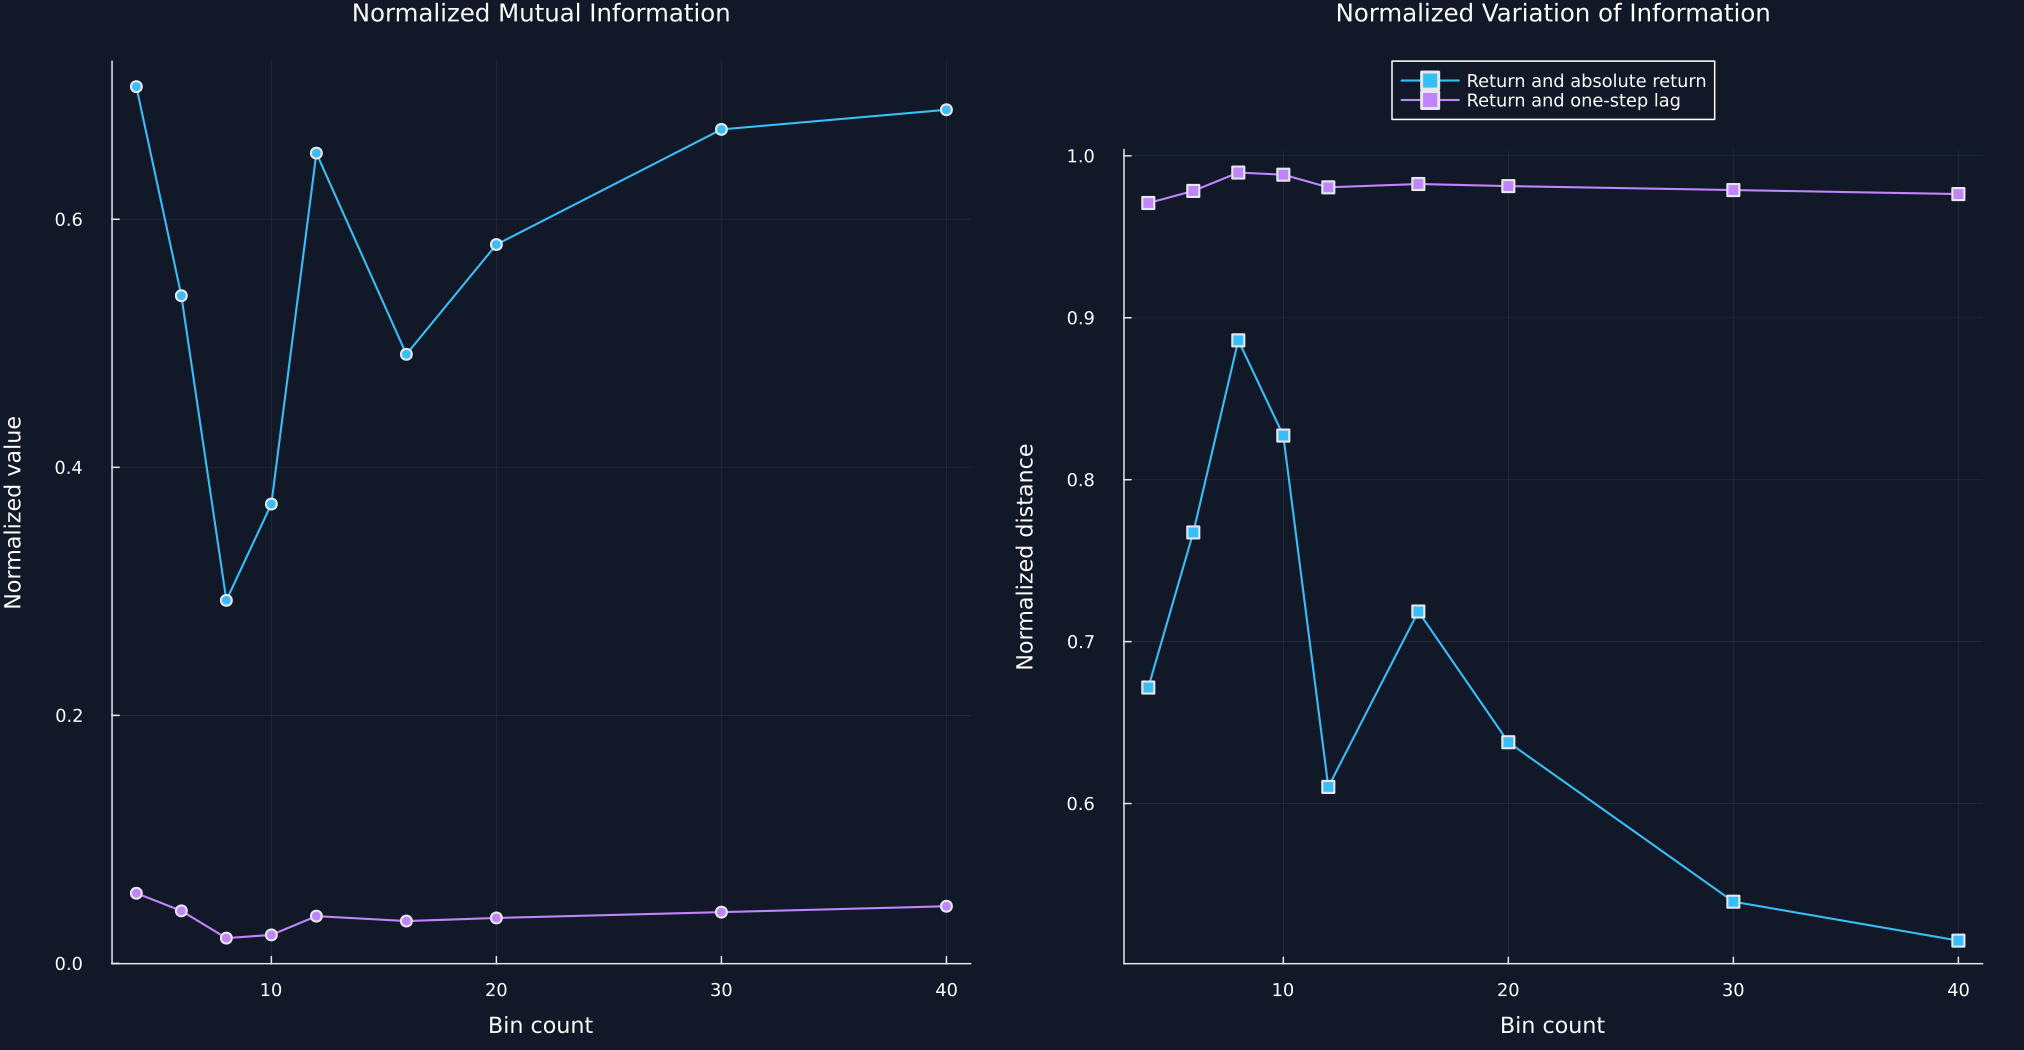

In [5]:
sample_grid = Float64.(0:699).*((length(return_values)-2)/699)
sample_grid .+= 1.
sample_grid[end] = length(return_values)-1
sample_positions = floor.(Int,sample_grid).+1
sampled_returns = return_values[sample_positions]
p1 = scatter(return_values[sample_positions.-1],sampled_returns;color=violet,markersize=2.5,markerstrokewidth=0,alpha=.65,title="Current Return and One-Step Lag",xlabel="Lagged log return",ylabel="Current log return",legend=false)
p2 = scatter(sampled_returns,abs.(sampled_returns);color=palette.cyan,markersize=2.5,markerstrokewidth=0,alpha=.65,title="Return and Absolute Return",xlabel="Log return",ylabel="Absolute log return",legend=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,650)),paths,"public_dependence_scatter")
p1 = plot(;title="Normalized Mutual Information",xlabel="Bin count",ylabel="Normalized value",legend=false)
p2 = plot(;title="Normalized Variation of Information",xlabel="Bin count",ylabel="Normalized distance",legend=:outertop,legend_column=1)
for (label,color) in [("Return and absolute return",palette.cyan),("Return and one-step lag",violet)]
    group = information_bin_sensitivity[information_bin_sensitivity.Pair.==label,:]
    plot!(p1,group.Bins,group[!,"Normalized mutual information"];color,marker=:circle,linewidth=1.4,label)
    plot!(p2,group.Bins,group[!,"Normalized variation of information"];color,marker=:square,linewidth=1.4,label)
end
save_figure(plot(p1,p2;layout=(1,2),size=(1350,700)),paths,"information_bin_sensitivity")
save_data(DataFrame(position=sample_positions,current=sampled_returns,lagged=return_values[sample_positions.-1]),paths,"public_scatter_sample");


## Tests

In [6]:
nonlinear_row = only(eachrow(dependence_summary[dependence_summary.Pair.=="Return and absolute return",:]))
lag_row = only(eachrow(dependence_summary[dependence_summary.Pair.=="Return and one-step lag",:]))
toy_x = repeat([1,2,3];inner=4)
toy_y = repeat([1,2,3];outer=4)
@assert nrow(dependence_summary)==4
@assert nrow(information_bin_sensitivity)==18
@assert maximum(information_identity_checks[!,"Absolute difference"])<1e-12
@assert abs(nonlinear_row.Correlation)<.15
@assert nonlinear_row["Normalized mutual information"]>lag_row["Normalized mutual information"]
@assert nonlinear_row["Normalized variation of information"]<lag_row["Normalized variation of information"]
@assert 0.0 <= nonlinear_row["Normalized mutual information"] <= 1.0
@assert 0.0 <= nonlinear_row["Normalized variation of information"] <= 1.0
@assert isapprox(calculate_mutual_information(toy_x,toy_x;norm=true),1.)
@assert isapprox(calculate_variation_of_information(toy_x,toy_x,3;norm=true),0.;atol=1e-12)
@assert isapprox(calculate_mutual_information(toy_x,toy_y;norm=true),0.;atol=.1)
@assert calculate_number_of_bins(length(nonlinear_x);correlation=cor(nonlinear_x,nonlinear_y))==nonlinear_row.Bins
@assert all(nrow(group)==9 for group in groupby(information_bin_sensitivity,:Pair))
cubic_nearest_error = only(known_truth_information_summary[(known_truth_information_summary.Relation.=="Monotone cubic relation").&(known_truth_information_summary.Method.=="Nearest-neighbor estimate"),"Root mean squared error"])
cubic_binned_error = only(known_truth_information_summary[(known_truth_information_summary.Relation.=="Monotone cubic relation").&(known_truth_information_summary.Method.=="Binned estimate"),"Root mean squared error"])
curved_screen = only(eachrow(nonlinear_screen_summary[nonlinear_screen_summary.Relation.=="Curved",:]))
independent_screen = only(eachrow(nonlinear_screen_summary[nonlinear_screen_summary.Relation.=="Independent",:]))
@assert cubic_nearest_error<cubic_binned_error
@assert curved_screen["Distance correlation"]>abs(curved_screen["Pearson correlation"])
@assert curved_screen["Nearest-neighbor information in bits"]>independent_screen["Nearest-neighbor information in bits"]
@assert independent_screen["Distance correlation"]<.15
@assert isfile(joinpath(paths.figures,"public_dependence_scatter.pdf"))
@assert isfile(joinpath(paths.figures,"information_bin_sensitivity.pdf"))
@assert isfile(joinpath(paths.figures,"known_truth_information.pdf"))
@assert isfile(joinpath(paths.figures,"controlled_dependence_cases.pdf"))
@assert isfile(joinpath(paths.tables,"known_truth_information_summary.tex"))
@assert isfile(joinpath(paths.tables,"nonlinear_screen_summary.tex"))
